# Dummy S2 pattern map generator

This notebook generates a simple **S2 pattern map** without running an optical photon propagation simulation. Together with the dummy S1 LCE map from `dummy_s1_lce_maps.ipynb` it allows to run the ember simulation and the abstrax processing chain end-to-end for a new detector geometry like XLZD. It is not a replacement for a proper optical simulation.

The map is saved in the format used by [fuse](https://github.com/XENONnT/fuse), the XENONnT simulation framework, which ember reads as well. The geometry and the PMT numbers come from ember's detector file `ember/config/detector.yaml`. The concepts apply to any dual-phase xenon TPC (XENON, LZ, XLZD, PandaX, ...). The notebook is also meant as a tutorial on what such a map has to contain.

### What is an S2 pattern map?

Ionization electrons produced by an interaction drift upwards to the liquid surface, where they are extracted into the gas phase by a strong electric field. In the gas they produce proportional scintillation light, the **S2** signal. The light is emitted in a thin layer of gas just above the liquid surface, close to the top PMT array. Hence, most of the S2 light is seen by the top PMTs directly above the extraction position, while the bottom array sees a rather uniform, dimmed light distribution.

The S2 pattern map stores for every extraction position $(x, y)$ and every PMT $i$ the fraction of the S2 light that is detected by PMT $i$:

$$p_i(x, y), \qquad \sum_i p_i(x, y) = 1$$

It is a 3D array with shape `(n_x, n_y, n_PMTs)`. Unlike the S1 map it has no z dependence, since the S2 light is always produced at the liquid surface. The hit pattern on the top array is what position reconstruction algorithms use to determine the (x, y) position of an event.

### How ember uses the map

For every extracted electron, ember (plugin `S2PhotonPropagation`, a port of the fuse plugin with the same name)
1. evaluates the map at the position where the electron is extracted (`x_interface`, `y_interface`),
2. sets switched-off PMTs to 0 and normalizes the pattern to 1,
3. assigns each S2 photon of this electron to a PMT with probability $p_i$.

Some consequences:
* Only the relative values between PMTs matter. The total amount of S2 light per electron is set elsewhere: the single electron gain $g_2 / \varepsilon_\mathrm{extraction}$ from `detector.yaml`, multiplied by the relative S2 correction map written at the end of this notebook. We nevertheless normalize the map to 1 at each position.
* The light of switched-off PMTs goes to the other PMTs, so they do not change the size of the S2.
* The AFT of the S2 is the AFT of this map. Unlike fuse, ember does not rescale or smear the AFT. (To use the map in fuse, set fuse's `s2_mean_area_fraction_top` to the same AFT or to a negative value, and `s2_aft_sigma` to 0.)

### Model of this dummy map

1. **PMT layout.** Both arrays consist of 3-inch PMTs on a hexagonal grid. The spacing of the grid is chosen such that the given number of PMTs covers the full TPC cross section.
2. **Top/bottom split.** A fraction AFT of the light is seen by the top array, the rest by the bottom array. The AFT is `s2_mean_area_fraction_top` in `detector.yaml` (0.8).
3. **Light on the top array.** The top light consists of two components:
    * a uniform component, distributed equally over all top PMTs, e.g. light reflected on the PTFE walls and the liquid surface,
    * a localized component, modeled as a 2D normal distribution centered at the extraction position. The light seen by a PMT is the normal distribution integrated over the PMT's circular face. The width $\sigma$ sets how much the light spreads over neighbouring PMTs: for $\sigma$ small compared to the PMT size almost all localized light ends up in a single PMT, for larger $\sigma$ it spreads over several PMTs.

    The fraction of light in the uniform component can be chosen freely.
4. **Light on the bottom array.** The bottom light is distributed equally over all bottom PMTs.

### Limitations

* No reflections on the TPC wall: close to the wall the part of the normal distribution falling outside the top array is redistributed over the PMTs inside, since the localized component is normalized to the PMTs.
* No PMT-to-PMT differences in quantum efficiency or gain, no electrode wires or meshes casting shadows, no dependence of the AFT on the position.

### Terminology

| Term | Meaning |
|---|---|
| S2 | Proportional scintillation signal produced by electrons extracted into the gas phase. |
| Extraction position | (x, y) position at which an electron leaves the liquid surface. Because of field distortions it can differ from the position of the interaction. |
| PMT / channel | Photosensor. In the map, every channel has its own entry along the last axis. |
| AFT | Area fraction top: fraction of the S2 seen by the top PMT array, $\mathrm{AFT} = S2_\mathrm{top} / S2_\mathrm{total}$. LZ uses the top-bottom asymmetry $\mathrm{TBA} = (T - B)/(T + B) = 2\,\mathrm{AFT} - 1$. |
| strax | Data processing framework used by ember and abstrax. ember's `RegularGridMap` (`ember/maps.py`) reads and interpolates the map. |
| fuse | XENON simulation framework that turns the energy deposits of a Geant4 simulation into simulated raw data. ember's plugins are ports of fuse. |

### Coordinate conventions

* $x$, $y$ in cm, origin on the TPC axis. Top and bottom array use the same coordinate system, i.e. the bottom array is not mirrored.
* PMT order: channels `0 ... n_top - 1` are the top array, followed by the bottom array. The order has to match the S1 map and the channel map of the simulation.

### Files written to `ember/dummy_maps/`

| File | Content |
|---|---|
| `s2_pattern_map_dummy.pkl` | The S2 pattern map. |
| `pmt_positions_dummy.csv` | The PMT positions of this layout, e.g. for position reconstruction. |
| `s2_correction_map_dummy.json` | The relative S2 light yield per extraction position, here constant 1. |

## Detector and model parameters

The detector parameters come from `ember/config/detector.yaml`, so the map always matches the detector of the simulation:

* `tpc_radius`: radius of the TPC in cm. All PMTs have to fit inside this radius.
* `number_of_pmts_top`, `number_of_pmts_bottom`: number of PMTs in the top and bottom array.
* `pmt_diameter`: outer diameter of the PMTs in cm (3 inch).
* `s2_area_fraction_top`: fraction of the S2 light seen by the top array (`s2_mean_area_fraction_top` in `detector.yaml`).

The parameters of the dummy light model are set here. Adapt them to your detector:

* `fraction_uniform_top`: fraction of the top light in the uniform component. The rest is in the localized (normal distributed) component.
* `sigma_gaussian`: width of the localized component in cm.
* `number_of_bins_in_x_or_y`: number of grid points of the map along x and y. Values in between are interpolated. The spacing should be small compared to `sigma_gaussian` and the PMT size.
* `number_of_samples_per_pmt`: number of points on each PMT face used to integrate the normal distribution.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import strax
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle

import ember
from ember.maps import encode_map_values, load_map, save_map_data
from ember.url_protocols import DUMMY_MAP_DIRECTORY

In [2]:
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")  # cm

number_of_pmts_top = strax.URLConfig.evaluate_dry("detector://n_top_pmts")
number_of_pmts_bottom = strax.URLConfig.evaluate_dry("detector://n_bottom_pmts")
total_number_of_pmts = number_of_pmts_top + number_of_pmts_bottom

pmt_diameter = strax.URLConfig.evaluate_dry("detector://pmt_diameter")  # cm, 3-inch PMTs

s2_area_fraction_top = strax.URLConfig.evaluate_dry("detector://s2_mean_area_fraction_top")

fraction_uniform_top = 0.15  # fraction of the top light distributed uniformly over all top PMTs
sigma_gaussian = 5  # cm, width of the localized light component

number_of_bins_in_x_or_y = 107  # grid spacing of about 1.25 cm, a quarter of sigma_gaussian
number_of_samples_per_pmt = 50

print(f"TPC radius: {tpc_radius} cm")
print(f"PMTs: {number_of_pmts_top} top, {number_of_pmts_bottom} bottom, diameter {pmt_diameter} cm")
print(f"S2 area fraction top: {s2_area_fraction_top}")
print(f"Grid spacing: {2 * tpc_radius / (number_of_bins_in_x_or_y - 1):.2f} cm")

TPC radius: 66.4 cm
PMTs: 253 top, 241 bottom, diameter 7.62 cm
S2 area fraction top: 0.8
Grid spacing: 1.25 cm


## Step 1: PMT layout

The PMTs are placed on a hexagonal grid, the densest packing of circles in a plane. We take the `n` grid points closest to the center. Since a hexagonal grid scales with its spacing (pitch), the set of the `n` closest points does not depend on the pitch. The pitch is then chosen as large as possible such that the outermost PMT still fits inside the TPC:

$$\mathrm{pitch} = \frac{R_\mathrm{TPC} - d_\mathrm{PMT}/2}{\rho_\mathrm{max}}$$

where $\rho_\mathrm{max}$ is the distance of the outermost point from the center for a grid with pitch 1. If the pitch is smaller than the PMT diameter, the PMTs would overlap and the given number of PMTs does not fit into the TPC.

If `n` does not fill a complete hexagonal ring, the outermost ring is only partially filled and the layout is not fully symmetric.

In [3]:
def hexagonal_pmt_positions(n_pmts, tpc_radius, pmt_diameter):
    """
    Place PMTs on a hexagonal grid which covers the TPC cross section.

    Args:
        n_pmts (int): Number of PMTs in the array.
        tpc_radius (float): Radius of the TPC (in cm).
        pmt_diameter (float): Diameter of a PMT (in cm).

    Returns:
        x, y (np.ndarray): PMT positions (in cm).
        pitch (float): Distance between neighbouring PMTs (in cm).
    """
    # Hexagonal grid with pitch 1, large enough to contain n_pmts points within a circle
    n_max = int(np.ceil(np.sqrt(n_pmts))) + 1
    i, j = np.meshgrid(np.arange(-n_max, n_max + 1), np.arange(-n_max, n_max + 1), indexing='ij')
    x = (i + 0.5*j).ravel()
    y = (np.sqrt(3)/2*j).ravel()

    # Take the n_pmts points closest to the center, ties are sorted by angle
    rho = np.round(np.sqrt(x**2 + y**2), 9)
    order = np.lexsort((np.arctan2(y, x), rho))[:n_pmts]
    x, y, rho = x[order], y[order], rho[order]

    if rho.max() == 0:
        return x, y, np.inf

    pitch = (tpc_radius - pmt_diameter/2)/rho.max()
    if pitch < pmt_diameter:
        raise ValueError(
            f'{n_pmts} PMTs with a diameter of {pmt_diameter} cm do not fit into a TPC with a radius of {tpc_radius} cm.'
        )
    return x*pitch, y*pitch, pitch

In [4]:
pmt_x_top, pmt_y_top, pitch_top = hexagonal_pmt_positions(number_of_pmts_top, tpc_radius, pmt_diameter)
pmt_x_bottom, pmt_y_bottom, pitch_bottom = hexagonal_pmt_positions(number_of_pmts_bottom, tpc_radius, pmt_diameter)

print(f'Top array: pitch {pitch_top:.2f} cm, gap between PMTs {pitch_top - pmt_diameter:.2f} cm')
print(f'Bottom array: pitch {pitch_bottom:.2f} cm, gap between PMTs {pitch_bottom - pmt_diameter:.2f} cm')

Top array: pitch 7.65 cm, gap between PMTs 0.03 cm
Bottom array: pitch 7.82 cm, gap between PMTs 0.20 cm


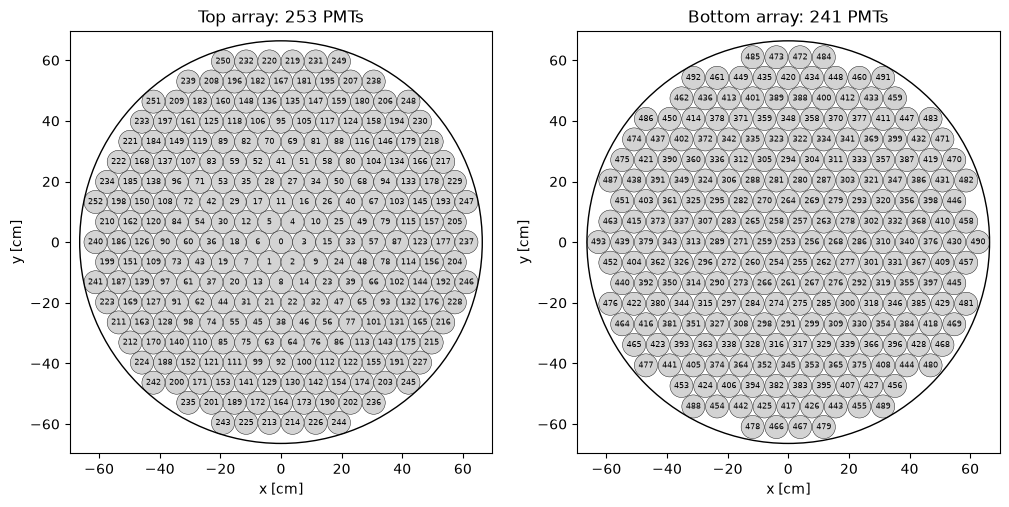

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, pmt_x, pmt_y, title, pmt_start_index in zip(
    axes, [pmt_x_top, pmt_x_bottom], [pmt_y_top, pmt_y_bottom], ['Top array', 'Bottom array'], [0, number_of_pmts_top]
):
    pmts = PatchCollection([Circle((x, y), pmt_diameter/2) for x, y in zip(pmt_x, pmt_y)], facecolor='lightgray', edgecolor='k', lw=0.3)
    ax.add_collection(pmts)
    ax.add_patch(Circle((0, 0), tpc_radius, fill=False, color='k', lw=1))
    ax.set_xlim(-1.05*tpc_radius, 1.05*tpc_radius)
    ax.set_ylim(-1.05*tpc_radius, 1.05*tpc_radius)
    ax.set_aspect('equal')
    ax.set_xlabel('x [cm]')
    ax.set_ylabel('y [cm]')
    ax.set_title(f'{title}: {len(pmt_x)} PMTs')
    for i, (x, y) in enumerate(zip(pmt_x, pmt_y), start=pmt_start_index):
        ax.text(x, y, f'{i}', fontsize=6, ha='center', va='center')

## Step 2: Light distribution for a single extraction position

The light seen by PMT $i$ for an electron extracted at $(x, y)$ is

$$p_i^\mathrm{top}(x, y) = \mathrm{AFT} \left[ \frac{f_\mathrm{uniform}}{n_\mathrm{top}} + (1 - f_\mathrm{uniform}) \frac{w_i(x, y)}{\sum_{j \in \mathrm{top}} w_j(x, y)} \right], \qquad p_i^\mathrm{bottom} = \frac{1 - \mathrm{AFT}}{n_\mathrm{bottom}}$$

where $w_i$ is the 2D normal distribution with width $\sigma$, centered at $(x, y)$, integrated over the face of PMT $i$. The integral is computed numerically by averaging the normal distribution over points spread evenly over the PMT face (a "sunflower" pattern). Constant factors of the normal distribution cancel in the normalization.

By construction the top PMTs receive a fraction AFT of the light and the sum over all PMTs is 1.

Electrons are only extracted inside the TPC. For grid points in the corners of the square map outside the TPC ($r > R_\mathrm{TPC}$), the pattern at the closest point on the TPC wall is used, so that interpolation close to the wall is not biased.

In [6]:
# Sample points on a PMT face relative to the PMT center (sunflower pattern)
k = np.arange(number_of_samples_per_pmt) + 0.5
sample_r = np.sqrt(k/number_of_samples_per_pmt)*pmt_diameter/2
sample_phi = k*np.pi*(3 - np.sqrt(5))
sample_dx = sample_r*np.cos(sample_phi)
sample_dy = sample_r*np.sin(sample_phi)

samples_x_top = pmt_x_top[:, np.newaxis] + sample_dx  # shape (n_top, n_samples)
samples_y_top = pmt_y_top[:, np.newaxis] + sample_dy

In [7]:
def s2_pattern(x, y):
    """
    Calculate the fraction of S2 light seen by each PMT.

    Args:
        x, y (np.ndarray): Extraction positions (in cm), shape (n_positions,).

    Returns:
        np.ndarray: Light fraction per PMT, shape (n_positions, total_number_of_pmts).
    """
    # Positions outside the TPC are moved radially onto the TPC wall
    r = np.sqrt(x**2 + y**2)
    scale = np.minimum(1, tpc_radius/np.maximum(r, 1e-12))
    x, y = x*scale, y*scale

    distance_squared = (x[:, np.newaxis, np.newaxis] - samples_x_top)**2 + (y[:, np.newaxis, np.newaxis] - samples_y_top)**2
    # Subtract the smallest distance per position to avoid that all weights underflow to 0 for small sigma
    distance_squared -= distance_squared.min(axis=(1, 2), keepdims=True)
    weights = np.exp(-distance_squared/(2*sigma_gaussian**2)).mean(axis=-1)  # shape (n_positions, n_top)
    weights /= weights.sum(axis=-1, keepdims=True)

    pattern_top = s2_area_fraction_top*(fraction_uniform_top/number_of_pmts_top + (1 - fraction_uniform_top)*weights)
    pattern_bottom = np.full((len(x), number_of_pmts_bottom), (1 - s2_area_fraction_top)/number_of_pmts_bottom)
    return np.concatenate([pattern_top, pattern_bottom], axis=-1)

Have a look at the light distribution on the top array for three extraction positions: at the center, at half radius and close to the wall. The view is zoomed in around the extraction position (red cross). The color shows the fraction of the total S2 light seen by each PMT:

(0, 0) cm: brightest PMT sees 0.191 of the S2 light, AFT = 0.800
(38, 4) cm: brightest PMT sees 0.144 of the S2 light, AFT = 0.800
(61, 0) cm: brightest PMT sees 0.298 of the S2 light, AFT = 0.800


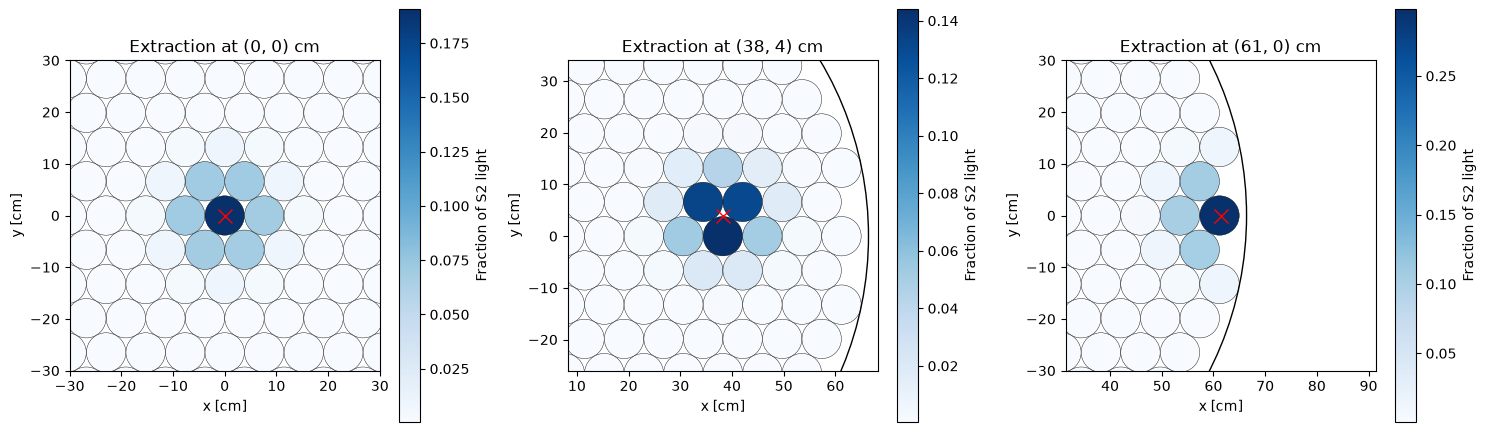

In [8]:
example_positions = np.array([[0, 0], [tpc_radius/2+5, 4], [tpc_radius - 5, 0]])
example_patterns = s2_pattern(example_positions[:, 0], example_positions[:, 1])
zoom = 30 # cm

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x0, y0), pattern in zip(axes, example_positions, example_patterns):
    pmts = PatchCollection([Circle((x, y), pmt_diameter/2) for x, y in zip(pmt_x_top, pmt_y_top)], cmap='Blues', edgecolor='k', lw=0.3)
    pmts.set_array(pattern[:number_of_pmts_top])
    ax.add_collection(pmts)
    ax.add_patch(Circle((0, 0), tpc_radius, fill=False, color='k', lw=1))
    ax.plot(x0, y0, 'x', color='red', ms=10)
    ax.set_xlim(x0 - zoom, x0 + zoom)
    ax.set_ylim(y0 - zoom, y0 + zoom)
    ax.set_aspect('equal')
    ax.set_xlabel('x [cm]')
    ax.set_ylabel('y [cm]')
    ax.set_title(f'Extraction at ({x0:.0f}, {y0:.0f}) cm')
    plt.colorbar(pmts, ax=ax, label='Fraction of S2 light')
plt.tight_layout()

for (x0, y0), pattern in zip(example_positions, example_patterns):
    print(f'({x0:.0f}, {y0:.0f}) cm: brightest PMT sees {pattern.max():.3f} of the S2 light, AFT = {pattern[:number_of_pmts_top].sum():.3f}')

## Step 3: Build the map

Evaluate the pattern on a square x-y grid. The map is computed row by row to limit the memory usage:

In [9]:
grid_x_or_y = np.linspace(-tpc_radius, tpc_radius, number_of_bins_in_x_or_y)

s2_map = np.zeros((number_of_bins_in_x_or_y, number_of_bins_in_x_or_y, total_number_of_pmts), dtype=np.float32)
for x_index, x in enumerate(grid_x_or_y):
    s2_map[x_index] = s2_pattern(np.full_like(grid_x_or_y, x), grid_x_or_y)

Check that at each position the light fractions sum to 1 and that the top array sees a fraction AFT of the light:

In [10]:
np.allclose(s2_map.sum(axis=-1), 1)  # This should be True

True

In [11]:
np.allclose(s2_map[..., :number_of_pmts_top].sum(axis=-1), s2_area_fraction_top)  # This should be True

True

The light seen by a single top PMT as a function of the extraction position. The PMT closest to half radius is shown, zoomed in around it. The light is localized around the PMT position, on top of the small uniform component:

Text(0, 0.5, 'y [cm]')

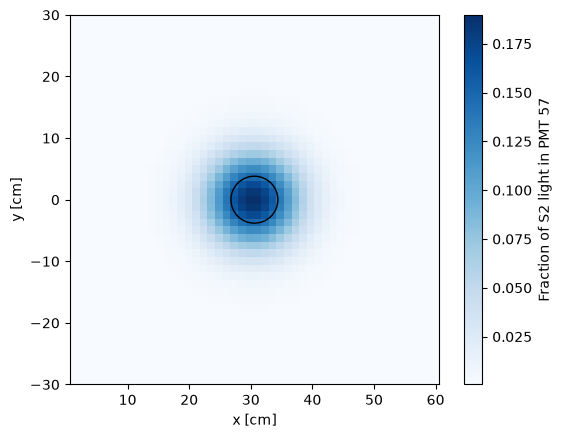

In [12]:
pmt_index = np.argmin((pmt_x_top - tpc_radius/2)**2 + pmt_y_top**2)
zoom = 30 # cm

plt.imshow(
    s2_map[:, :, pmt_index].T, origin='lower', cmap='Blues',
    extent=[-tpc_radius, tpc_radius, -tpc_radius, tpc_radius]
)
plt.colorbar(label=f'Fraction of S2 light in PMT {pmt_index}')
plt.gca().add_patch(Circle((pmt_x_top[pmt_index], pmt_y_top[pmt_index]), pmt_diameter/2, fill=False, color='k', lw=1))
plt.xlim(pmt_x_top[pmt_index] - zoom, pmt_x_top[pmt_index] + zoom)
plt.ylim(pmt_y_top[pmt_index] - zoom, pmt_y_top[pmt_index] + zoom)
plt.xlabel('x [cm]')
plt.ylabel('y [cm]')

## Save the map

The map is stored as a pickled dictionary in the same format as the S1 LCE map. ember reads it with `ember_map://s2_pattern_map_dummy.pkl` (and fuse with its `pattern_map` protocol):

| Key | Content |
|---|---|
| `coordinate_system` | Grid of the map as `[name, (min, max, n_points)]` for x and y in cm. The grid points are `np.linspace(min, max, n_points)`, i.e. they must be evenly spaced. |
| `map` | The light fractions with shape `(n_x, n_y, n_PMTs)`. |
| `quantized` | The values are stored as integers in units of this number to reduce the file size. With many PMTs the values per PMT are small, hence $10^{-8}$ is used. |
| `compressed` | Compressor, integer type and shape of the compressed `map` (zstd, uint32). |
| `name`, `description`, `timestamp` | Metadata. |

`encode_map_values` quantizes and compresses the map, `save_map_data` writes the file:

In [13]:
s2_pattern_map = {
    "coordinate_system": [
        ["x", (-float(tpc_radius), float(tpc_radius), number_of_bins_in_x_or_y)],
        ["y", (-float(tpc_radius), float(tpc_radius), number_of_bins_in_x_or_y)],
    ],
    "description": (
        f"Dummy S2 pattern map for a TPC with R={tpc_radius} cm and "
        f"{number_of_pmts_top} top / {number_of_pmts_bottom} bottom 3-inch PMTs on a hexagonal grid. "
        f"AFT={s2_area_fraction_top}, top light: {fraction_uniform_top} uniform and "
        f"{1 - fraction_uniform_top:.2f} normal distributed with sigma={sigma_gaussian} cm, bottom light uniform."
    ),
    "timestamp": time.time(),
    "name": "Dummy S2 pattern map",
    "map": s2_map,
}

output_file = DUMMY_MAP_DIRECTORY / "s2_pattern_map_dummy.pkl"
save_map_data(encode_map_values(s2_pattern_map, quantized=1e-8), output_file)
print("Saved", output_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/s2_pattern_map_dummy.pkl


Also save the PMT positions of this layout, e.g. for position reconstruction or for plotting hit patterns during processing. The file contains the channel number `i`, the array (`top` or `bottom`) and the position `x`, `y` in cm:

In [14]:
pmt_positions = pd.DataFrame({
    "i": np.arange(total_number_of_pmts),
    "array": ["top"] * number_of_pmts_top + ["bottom"] * number_of_pmts_bottom,
    "x": np.concatenate([pmt_x_top, pmt_x_bottom]),
    "y": np.concatenate([pmt_y_top, pmt_y_bottom]),
})

pmt_positions_file = DUMMY_MAP_DIRECTORY / "pmt_positions_dummy.csv"
pmt_positions.to_csv(pmt_positions_file, index=False)
pmt_positions.head()

,i,array,x,y
0,0,top,0.000000,0.000000
1,1,top,-3.823293,-6.622137
2,2,top,3.823293,-6.622137
3,3,top,7.646586,0.000000
4,4,top,3.823293,6.622137


Now load the saved map the same way the simulation does and check the result at the example positions. The light fractions should sum to 1 and the AFT should equal `s2_area_fraction_top`:

In [15]:
itp_map = load_map(output_file)

loaded_patterns = itp_map(example_positions)
print("Sum over all PMTs:", loaded_patterns.sum(axis=-1))
print("AFT:", loaded_patterns[:, :number_of_pmts_top].sum(axis=-1))

Sum over all PMTs: [1.00000142 1.00000136 1.00000149]
AFT: [0.80000034 0.80000028 0.80000041]


## S2 correction map

The number of S2 photons produced by one extracted electron is

$$\mu(x, y) = \frac{c_{xy}(x, y) \cdot g_\mathrm{SE}}{1 + p_\mathrm{DPE}}, \qquad g_\mathrm{SE} = \frac{g_2}{\varepsilon_\mathrm{extraction}}$$

where $g_\mathrm{SE}$ is the single electron gain in PE per extracted electron and $p_\mathrm{DPE}$ the probability of a double photoelectron emission. The **S2 correction map** $c_{xy}(x, y)$ is a relative light yield without units. In a real detector it is measured, e.g. with $^{83m}$Kr, and describes for example the sagging of the anode or a non-uniform gas gap. Its convention is a mean of 1 over the extraction area, so $g_2$ is the average over the TPC.

Our dummy map is constant 1. A constant map needs only two grid points per axis:

In [16]:
s2_correction_map = {
    "name": "s2_correction_map_dummy",
    "description": "Relative S2 light yield c_xy(x, y), constant 1 (mean 1 over the extraction area).",
    "coordinate_system": [
        ["x", [-float(tpc_radius), float(tpc_radius), 2]],
        ["y", [-float(tpc_radius), float(tpc_radius), 2]],
    ],
    "map": [[1.0, 1.0], [1.0, 1.0]],
}

correction_map_file = DUMMY_MAP_DIRECTORY / "s2_correction_map_dummy.json"
save_map_data(s2_correction_map, correction_map_file)
print("Relative light yield at the example positions:", load_map(correction_map_file)(example_positions))

Relative light yield at the example positions: [1. 1. 1.]
